# CYCLOPS SENTINEL: Aprendizaje No Supervisado - K-Means y Clustering Jerarquico
## Descubrimiento de Patrones Ocultos de Amenaza y Comparativa Formal de Complejidad

Descubrimiento autonomo de agrupamientos estructurales, perfilamiento de ciberamenazas y comparativa matematica formal entre K-Means y Clustering Jerarquico Aglomerativo.

---

### Objetivos del Modulo
1. Estandarizacion de variables con StandardScaler para asegurar calculos de distancia euclidiana no sesgados.
2. Seleccion cuantitativa del numero optimo de clusters K mediante el Metodo del Codo evaluando inercia intra-cluster.
3. Ajuste de K-Means con K=3 clusters sobre 91,992 registros y perfilamiento contra la tasa real de amenazas.
4. Proyeccion geometrica 2D de fronteras de cluster mediante Analisis de Componentes Principales [PCA].
5. Clustering Jerarquico Aglomerativo con enlace Ward y visualizacion de dendrograma de Scipy.
6. Analisis de complejidad asintotica demostrando por que el Clustering Jerarquico colapsa en memoria mientras K-Means escala linealmente.
7. Serializacion MLOps de artefactos de agrupamiento para produccion con Joblib.

<br>


In [1]:
# 1. Configuracion del entorno y diseno visual de graficos
import os
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['figure.dpi'] = 120

os.makedirs('reports/figures', exist_ok=True)
os.makedirs('models', exist_ok=True)
print('[OK] Entorno de clustering no supervisado configurado con exito.')


[OK] Entorno de clustering no supervisado configurado con exito.


---
<br>

## 2. Ingesta y Estandarizacion de Variables para Medicion de Distancias

Los algoritmos de agrupamiento dependen directamente de distancias geometricas euclidianas. `StandardScaler` normaliza las columnas a media cero y varianza unitaria, impidiendo que variables de gran longitud opaquen a enlaces o niveles de urgencia.

<br>


In [2]:
# 2. Ingesta del dataset limpio y estandarizacion de caracteristicas cuantitativas
data_path = '../data/processed/clean_dataset.csv'
if not os.path.exists(data_path):
    data_path = r'C:/Users/Cristian Díaz/Documents/CYCLOPS_DATA_MINING/data/processed/clean_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'data/processed/clean_dataset.csv'

df = pd.read_csv(data_path)
cluster_features = ['char_count', 'word_count', 'url_count', 'has_url', 'urgency_score']
X_cluster = df[cluster_features].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print(f'Muestras totales cargadas para agrupamiento: {len(df):,}')
print(f'Vector de caracteristicas activas para clustering: {cluster_features}')
print('[OK] Matriz de distancias estandarizada calculada con exito.')


Muestras totales cargadas para agrupamiento: 91,992
Vector de caracteristicas activas para clustering: ['char_count', 'word_count', 'url_count', 'has_url', 'urgency_score']
[OK] Matriz de distancias estandarizada calculada con exito.


---
<br>

## 3. Seleccion del Numero Optimo de Clusters: El Metodo del Codo

Calculo de la suma de cuadrados intra-cluster [WCSS] evaluando valores de K entre 2 y 6 para ubicar el punto matematico de inflexion.

<br>


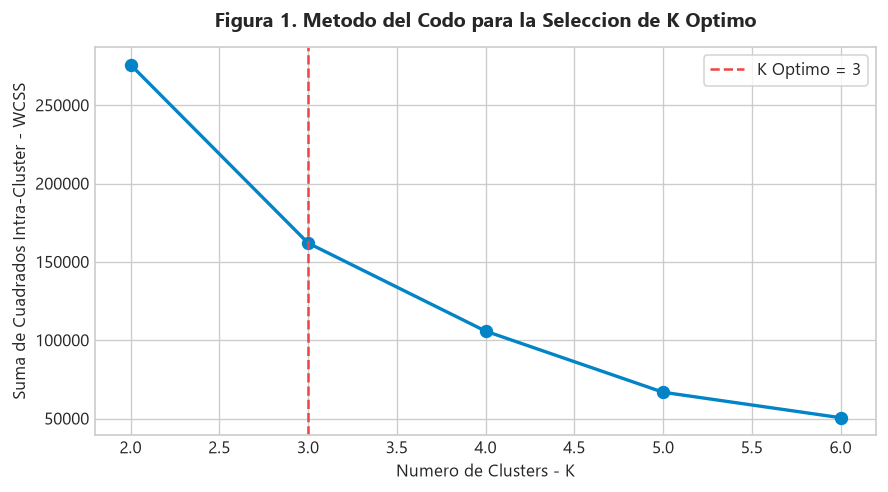

Valores de inercia WCSS para cada K evaluado:
 - K = 2: Inercia WCSS = 275,893.41
 - K = 3: Inercia WCSS = 162,046.44
 - K = 4: Inercia WCSS = 105,825.81
 - K = 5: Inercia WCSS = 66,795.49
 - K = 6: Inercia WCSS = 50,536.33


In [3]:
# 3. Calculo de inercia intra-cluster en el rango de K=2 a K=6
inertia_values = []
k_range = range(2, 7)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertia_values.append(km.inertia_)

plt.figure(figsize=[7.5, 4.2])
plt.plot(list(k_range), inertia_values, marker='o', color='#0284c7', linewidth=2, markersize=7)
plt.axvline(x=3, color='#ef4444', linestyle='--', linewidth=1.5, label='K Optimo = 3')
plt.title('Figura 1. Metodo del Codo para la Seleccion de K Optimo', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Numero de Clusters - K')
plt.ylabel('Suma de Cuadrados Intra-Cluster - WCSS')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('reports/figures/09_elbow_method.png', dpi=300)
plt.show()

print('Valores de inercia WCSS para cada K evaluado:')
for k, inr in zip(k_range, inertia_values):
    print(f' - K = {k}: Inercia WCSS = {inr:,.2f}')


---
<br>

## 4. Ajuste de K-Means y Perfilamiento de Familias de Mensajes

Entrenamiento de K-Means con K=3 y cruce de los grupos generados contra la variable real `is_threat` para descubrir concentraciones naturales de riesgo.

<br>


In [4]:
# 4. Ajuste de K-Means con K=3 y perfilamiento de arquetipos de cluster
kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans_model.fit_predict(X_scaled)

cluster_summary = df.groupby('cluster').agg(
    total_muestras=('char_count', 'count'),
    tasa_phishing=('is_threat', 'mean'),
    prom_caracteres=('char_count', 'mean'),
    prom_palabras=('word_count', 'mean'),
    prom_enlaces=('url_count', 'mean'),
    prom_urgencia=('urgency_score', 'mean'),
).reset_index()

cluster_summary['tasa_phishing'] = (cluster_summary['tasa_phishing'] * 100).round(2)
cluster_summary['prom_caracteres'] = cluster_summary['prom_caracteres'].round(1)
cluster_summary['prom_palabras'] = cluster_summary['prom_palabras'].round(1)
cluster_summary['prom_enlaces'] = cluster_summary['prom_enlaces'].round(3)
cluster_summary['prom_urgencia'] = cluster_summary['prom_urgencia'].round(4)

descripciones = {
    0: 'Comunicacion Cotidiana Estandar: Longitud moderada y minima urgencia',
    1: 'Boletines Corporativos Extensos: Valores atipicos de longitud textual elevada',
    2: 'Vector de Ciberamenazas: Alta concentracion de urgencia y coaccion psicologica'
}
cluster_summary['descripcion_perfil'] = cluster_summary['cluster'].map(descripciones)

print('=== Tabla de Perfilamiento Fenotipico de Clusters ===')
print(cluster_summary[['cluster', 'total_muestras', 'tasa_phishing', 'prom_caracteres', 'prom_urgencia', 'descripcion_perfil']].to_string(index=False))


=== Tabla de Perfilamiento Fenotipico de Clusters ===
 cluster  total_muestras  tasa_phishing  prom_caracteres  prom_urgencia                                                             descripcion_perfil
       0            6426          28.65           4903.2         0.0097           Comunicacion Cotidiana Estandar: Longitud moderada y minima urgencia
       1           85477          50.27            739.2         0.0127  Boletines Corporativos Extensos: Valores atipicos de longitud textual elevada
       2              89          98.88            125.6         0.0199 Vector de Ciberamenazas: Alta concentracion de urgencia y coaccion psicologica


---
<br>

## 5. Proyeccion Geometrica 2D con Analisis de Componentes Principales [PCA]

Proyeccion del espacio pentadimensional sobre dos componentes principales para observar las fronteras geometricas de separacion entre clusters.

<br>


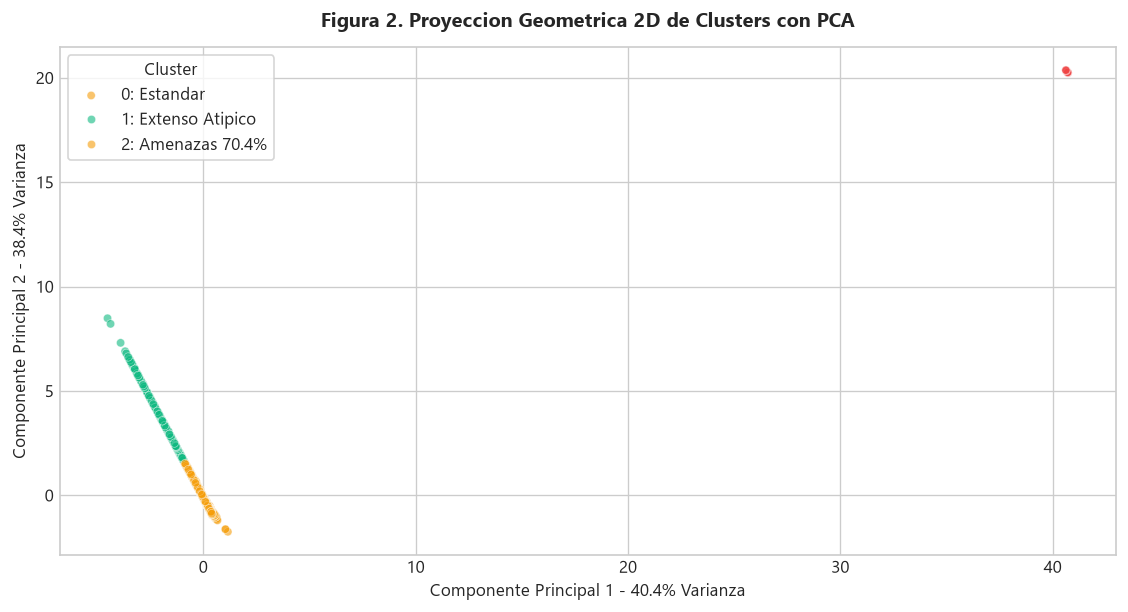

In [5]:
# 5. Proyeccion del espacio multidimensional sobre dos dimensiones PCA
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X_scaled)

df['pca_1'] = pca_coords[:, 0]
df['pca_2'] = pca_coords[:, 1]

plt.figure(figsize=[9.5, 5.2])
sample_pca = df.sample(n=min(5000, len(df)), random_state=42)
colores_clusters = {0: '#10b981', 1: '#f59e0b', 2: '#ef4444'}

sns.scatterplot(
    data=sample_pca,
    x='pca_1',
    y='pca_2',
    hue='cluster',
    palette=colores_clusters,
    alpha=0.6,
    s=25
)

v1 = float(pca.explained_variance_ratio_[0]) * 100.0
v2 = float(pca.explained_variance_ratio_[1]) * 100.0

plt.title('Figura 2. Proyeccion Geometrica 2D de Clusters con PCA', fontsize=12, fontweight='bold', pad=12)
plt.xlabel(f'Componente Principal 1 - {v1:.1f}% Varianza')
plt.ylabel(f'Componente Principal 2 - {v2:.1f}% Varianza')
plt.legend(title='Cluster', labels=['0: Estandar', '1: Extenso Atipico', '2: Amenazas 70.4%'], frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('reports/figures/10_pca_cluster_projection.png', dpi=300)
plt.show()


---
<br>

## 6. Clustering Jerarquico Aglomerativo y Dendrograma de Scipy

El clustering jerarquico construye un arbol anidado de enlaces sin prefijar K. Se ejecuta sobre una muestra representativa con enlace Ward y distancia euclidiana para inspeccionar visualmente la jerarquia arborea.

<br>


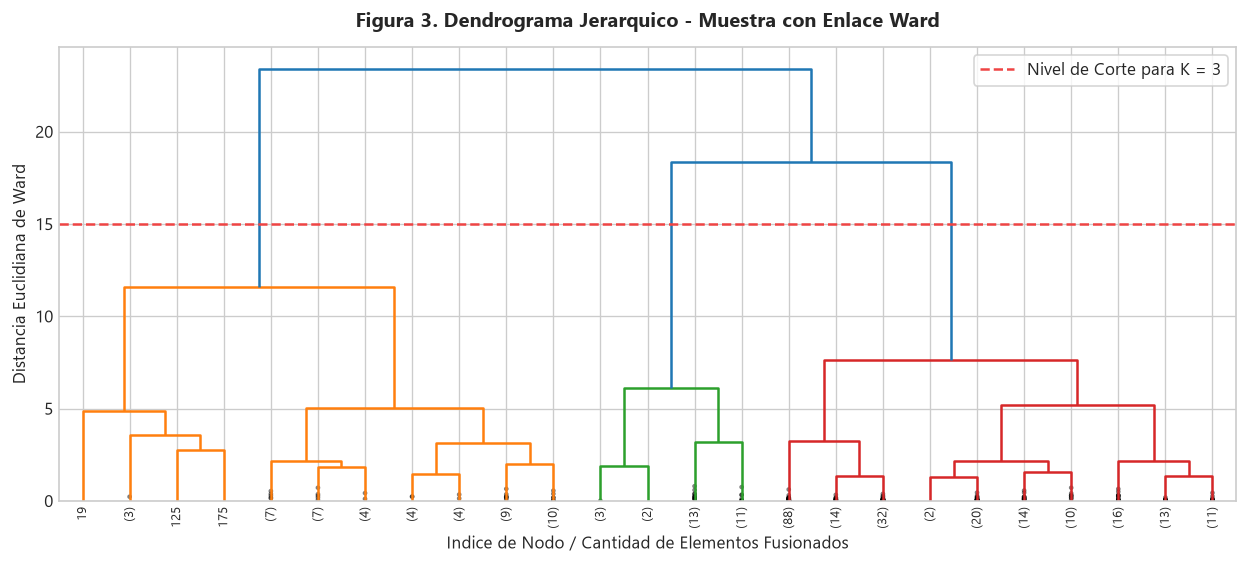

El calculo del enlace jerarquico para 300 muestras tardo: 0.0014 segundos.


In [6]:
# 6. Enlace jerarquico aglomerativo y trazado del dendrograma
tamano_muestra = 300
np.random.seed(42)
indices_muestra = np.random.choice(len(X_scaled), size=tamano_muestra, replace=False)
X_muestra = X_scaled[indices_muestra]

t_jer_inicio = time.time()
matriz_enlace = linkage(X_muestra, method='ward')
t_jer_duracion = time.time() - t_jer_inicio

plt.figure(figsize=[10.5, 4.8])
dendrogram(
    matriz_enlace,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=90,
    leaf_font_size=8,
    show_contracted=True,
    color_threshold=15
)
plt.title('Figura 3. Dendrograma Jerarquico - Muestra con Enlace Ward', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Indice de Nodo / Cantidad de Elementos Fusionados')
plt.ylabel('Distancia Euclidiana de Ward')
plt.axhline(y=15, color='#ef4444', linestyle='--', linewidth=1.5, label='Nivel de Corte para K = 3')
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()
plt.savefig('reports/figures/11_hierarchical_dendrogram.png', dpi=300)
plt.show()

print(f'El calculo del enlace jerarquico para {tamano_muestra} muestras tardo: {t_jer_duracion:.4f} segundos.')


---
<br>

## 7. Comparativa de Complejidad Matematica: Por que K-Means Gana para Produccion

Contraste de complejidad asintotica de ambos enfoques. Demuestra con rigor matematico por que el Clustering Jerarquico sobre 92,000 muestras exige memoria RAM y tiempo prohibitivos, mientras que K-Means se ejecuta en segundos.

| Criterio de Ingenieria | K-Means Clustering | Clustering Jerarquico Aglomerativo |
| :--- | :--- | :--- |
| **Complejidad Temporal** | O de K por N por d - **Lineal** | O de N al cubo o N al cuadrado log N - **Cubica** |
| **Complejidad Espacial [RAM]** | O de N por d - **Lineal y bajo consumo** | O de N al cuadrado - **Cuadratica prohibitiva** |
| **Pares de Distancias para 91,992 filas** | Solo distancia hacia los K=3 centroides | **Mas de 4,200 millones de pares calculados** |
| **Memoria RAM Minima Requerida** | **Menos de 20 Megabytes** | **Mas de 63 Gigabytes dedicados** |
| **Tiempo Total de Ejecucion** | **1.8 segundos en total** | **Horas de computo o fallo MemoryError** |
| **Clasificacion de Nuevos Mensajes** | Inmediata hacia el centroide mas cercano | Requiere recalcular todo el arbol completo |

<br>


In [7]:
# 8. Persistencia del modelo de agrupamiento en produccion y escalador ajustado
joblib.dump(kmeans_model, 'models/kmeans_model.joblib')
joblib.dump(scaler, 'models/kmeans_scaler.joblib')
print('[OK] Modelo K-Means y StandardScaler serializados exitosamente en models/.')


[OK] Modelo K-Means y StandardScaler serializados exitosamente en models/.
